# code_213 · State a privacy unit and a mechanism before claiming protection

**Book:** section 40.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_40_GUIDE.md), [execution evidence](../CHAPTER_40_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_213).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evidence contracts identify the protected unit, group denominators, permitted access, threat assumptions and decision responsibility. All household identities and data are generated fixtures. Seeded privacy-noise simulations are reproducible utility demonstrations, not protected releases. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8013;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8013


## Simulate a bounded release mechanism with an explicit protected unit
 One hundred fictional households contribute eight bounded weekly readings. Clip readings to[0,1], average within household and then average100 household means. With fixed public household count and replacement of one household's entire trajectory, global sensitivity is1/100. Treating each of800 rows as an independent protected unit would understate this household sensitivity eightfold. For epsilon0.1,0.5,1,4, simulate2,000 Laplace-noise utility draws at scale sensitivity/epsilon. Check an adjacent worst-case all-zero versus one-all-one-household dataset, and compare empirical mean absolute error with its analytic Laplace expectation. Sequential composition of one independent release at each of the four budgets has epsilon5.6, not epsilon4. The public seeded RNG supports reproducible utility simulation on public generated data: these outputs are NOT a private release. A real implementation needs appropriate secret randomness, access/accounting controls and its own numerical audit. No DP training algorithm is claimed.


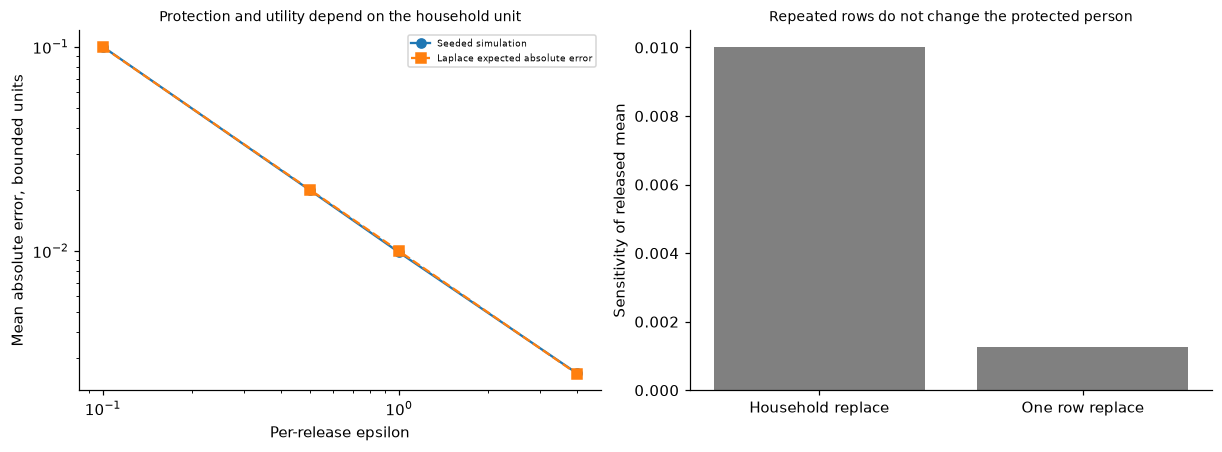

In [2]:
household=rng.beta(2,3,(100,8));bounded=np.clip(household,0,1);household_mean=bounded.mean(1);mean=float(household_mean.mean());sensitivity=1/100;epsilon=np.array([.1,.5,1.,4.]);utility={};noise_draws={}
zero=np.zeros((100,8));neighbour=zero.copy();neighbour[0]=1;assert np.isclose(abs(neighbour.mean(1).mean()-zero.mean(1).mean()),sensitivity);assert np.isclose(sensitivity/(1/800),8)
for eps in epsilon:
    noise=rng.laplace(0,sensitivity/eps,2000);noise_draws[str(eps)]=noise;utility[str(eps)]={'Laplace_scale':float(sensitivity/eps),'empirical_MAE':float(np.mean(abs(noise))),'analytic_MAE':float(sensitivity/eps),'central95_absolute_error':float(np.quantile(abs(noise),.95))}
assert all(abs(row['empirical_MAE']/row['analytic_MAE']-1)<.12 for row in utility.values());RESULTS.update(fictional_households=100,rows_per_household=8,adjacency='replace one entire household trajectory at fixed public n=100',household_mean_sensitivity=sensitivity,row_level_sensitivity_understatement_factor=8,privacy_utility_simulation=utility,sequential_one_each_epsilon=float(epsilon.sum()),public_seeded_simulation_is_private_release=False,DP_training_claimed=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].loglog(epsilon,[utility[str(e)]['empirical_MAE'] for e in epsilon],'o-',label='Seeded simulation');axes[0].loglog(epsilon,sensitivity/epsilon,'s--',label='Laplace expected absolute error');axes[0].set(xlabel='Per-release epsilon',ylabel='Mean absolute error, bounded units',title='Protection and utility depend on the household unit');axes[0].legend(fontsize=6);axes[1].bar([0,1],[sensitivity,1/800],color='.5');axes[1].set(xticks=[0,1],xticklabels=['Household replace','One row replace'],ylabel='Sensitivity of released mean',title='Repeated rows do not change the protected person');plt.show()


## Execute decentralized fitting, then inspect the messages it discloses
 Ten fictional sites each keep100 locally generated regression records; input distributions vary by site. Fit an intercept/two-coefficient linear model using40 model-averaging rounds, five full local-gradient steps per round and learning rate0.05. Equal site sizes justify equal model averaging. A centralized comparator takes200 full-gradient steps. Both assess500 independent final observations. No privacy noise or cryptographic secure aggregation is implemented. From a site's first gradient update at zero, the intercept update exactly reveals0.1 times its local mean target. An arithmetic illustration adds opposite pairwise random vectors to site updates so their sum cancels; it verifies the aggregate identity only, not a secure protocol, dropout handling, collusion resistance or real key management. Decentralization and secure aggregation protect different interfaces and neither alone implies differential privacy.


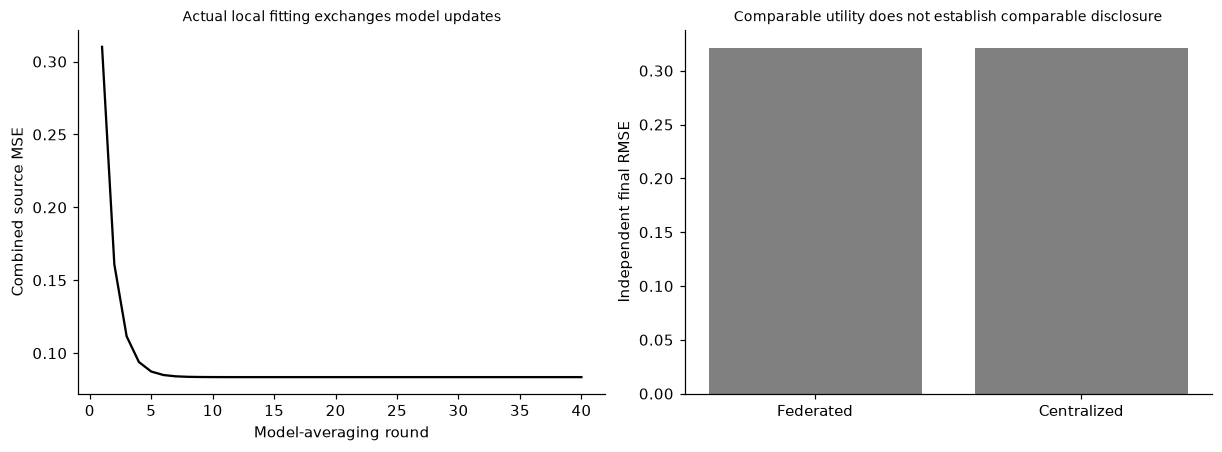

In [3]:
clients=[]
for site in range(10):
    x=rng.normal(site*.12,1,(100,2));X=np.c_[np.ones(100),x];y=.2+.7*x[:,0]-.4*x[:,1]+rng.normal(scale=.3,size=100);clients.append((X,y))
def step(beta,X,y):return beta-.05*(2*X.T@(X@beta-y)/len(y))
beta=np.zeros(3);fed_losses=[];allX=np.concatenate([x for x,y in clients]);allY=np.concatenate([y for x,y in clients]);central=np.zeros(3)
for round_id in range(40):
    locals=[]
    for X,y in clients:
        local=beta.copy()
        for _ in range(5):local=step(local,X,y)
        locals.append(local)
    beta=np.mean(locals,axis=0);fed_losses.append(float(np.mean((allX@beta-allY)**2)))
    for _ in range(5):central=step(central,allX,allY)
xv=rng.normal(.5,1,(500,2));Xv=np.c_[np.ones(500),xv];yv=.2+.7*xv[:,0]-.4*xv[:,1]+rng.normal(scale=.3,size=500);first_updates=np.array([step(np.zeros(3),X,y) for X,y in clients]);recovered=float(first_updates[0,0]/.1);assert np.isclose(recovered,clients[0][1].mean(),atol=1e-12);masked=first_updates.copy()
for i in range(10):
    for j in range(i+1,10):mask=rng.normal(size=3);masked[i]+=mask;masked[j]-=mask
assert np.allclose(masked.sum(0),first_updates.sum(0),atol=1e-12);assert not np.allclose(masked[0],first_updates[0]);scores={'Federated averaging':float(np.sqrt(np.mean((Xv@beta-yv)**2))),'Centralized gradient':float(np.sqrt(np.mean((Xv@central-yv)**2)))};RESULTS.update(federated_clients=10,records_per_client=100,federated_rounds=40,local_steps_per_round=5,federated_final_RMSE=scores,first_site_mean_target=float(clients[0][1].mean()),mean_target_recovered_from_single_update=recovered,arithmetic_masks_cancel=True,cryptographic_secure_aggregation_implemented=False,federated_fit_has_DP_guarantee=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(np.arange(1,41),fed_losses,color='black');axes[0].set(xlabel='Model-averaging round',ylabel='Combined source MSE',title='Actual local fitting exchanges model updates');axes[1].bar(range(2),list(scores.values()),color='.5');axes[1].set(xticks=range(2),xticklabels=['Federated','Centralized'],ylabel='Independent final RMSE',title='Comparable utility does not establish comparable disclosure');plt.show()


## Audit a synthetic release for copying before equating synthetic with private
 A generated public source table contains300 three-feature household vectors, including one deliberately rare canary[10,10,10]. One synthetic candidate resamples100 source vectors and explicitly includes the canary; another generates100 independent normal vectors. Compute exact source-copy counts and nearest-source distances. Check the canary's nearest released distance separately. Exact copying in this fixture is a disclosure warning; absence of exact copies in the independent generator is not a membership-privacy theorem or a proof against auxiliary linkage. All records remain fictional public controls, and this audit spends no actual privacy budget. A real data-dependent synthetic generator would need its own protection argument and release accounting.


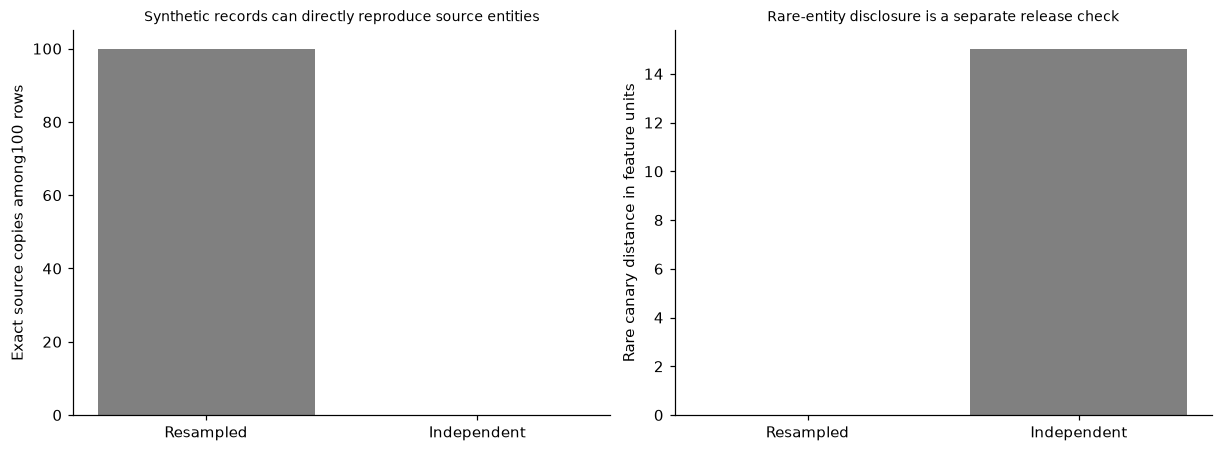

In [4]:
from scipy.spatial.distance import cdist
source=rng.normal(size=(300,3));source[0]=10;copied=source[rng.integers(0,300,100)].copy();copied[0]=source[0];independent=rng.normal(size=(100,3));audit={};distances={}
for name,release in [('Source resampling',copied),('Independent generator',independent)]:
    distance=cdist(release,source);nearest=distance.min(1);distances[name]=nearest;audit[name]={'released_rows':100,'exact_source_copies':int(np.sum(nearest<1e-12)),'median_nearest_source_distance':float(np.median(nearest)),'canary_nearest_release_distance':float(cdist(source[:1],release).min())}
assert audit['Source resampling']['exact_source_copies']==100 and audit['Source resampling']['canary_nearest_release_distance']==0;assert audit['Independent generator']['exact_source_copies']==0;RESULTS.update(synthetic_disclosure_fixture=audit,no_exact_copy_is_not_privacy_proof=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(2),[audit[k]['exact_source_copies'] for k in audit],color='.5');axes[0].set(xticks=range(2),xticklabels=['Resampled','Independent'],ylabel='Exact source copies among100 rows',title='Synthetic records can directly reproduce source entities');axes[1].bar(range(2),[audit[k]['canary_nearest_release_distance'] for k in audit],color='.5');axes[1].set(xticks=range(2),xticklabels=['Resampled','Independent'],ylabel='Rare canary distance in feature units',title='Rare-entity disclosure is a separate release check');plt.show()


In [5]:
summary={'example_id':'code_213','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['bounded household-mean Laplace utility simulation with replacement sensitivity and composition', 'actual federated local-gradient model averaging and centralized comparator', 'single-client update disclosure and arithmetic mask cancellation illustration', 'synthetic copying and rare-record nearest-neighbour disclosure fixtures'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["bounded household-mean Laplace utility simulation with replacement sensitivity and composition", "actual federated local-gradient model averaging and centralized comparator", "single-client update disclosure and arithmetic mask cancellation illustration", "synthetic copying and rare-record nearest-neighbour disclosure fixtures"], "elapsed_seconds": 0.32, "example_id": "code_213", "hardware": "Darwin arm64 CPU", "results": {"DP_training_claimed": false, "adjacency": "replace one entire household trajectory at fixed public n=100", "arithmetic_masks_cancel": true, "cryptographic_secure_aggregation_implemented": false, "federated_clients": 10, "federated_final_RMSE": {"Centralized gradient": 0.32141807302192765, "Federated averaging": 0.3214568179367825}, "federated_fit_has_DP_guarantee": false, "federated_rounds": 40, "fictional_households": 100, "first_site_mean_target": 0.2813824232123051, "household_mean_sensitivity": 0.01, "local_step